In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CSV_PATH = Path("../raw/airbus-ship-detection/train_ship_segmentations_v2.csv")
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")

MASK_SIZE = 768

In [2]:
def decode_rle(encoded_pixels, height=768, width=768):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels):
        return mask.reshape((height, width))

    values = np.asarray(
        encoded_pixels.split(),
        dtype=np.int64,
    )

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    # Airbus RLE uses column-major order.
    return mask.reshape((width, height)).T

In [3]:
annotations = pd.read_csv(CSV_PATH)


def get_image_mask(image_id):
    rows = annotations.loc[
        annotations["ImageId"] == image_id,
        "EncodedPixels",
    ]

    combined_mask = np.zeros(
        (MASK_SIZE, MASK_SIZE),
        dtype=np.uint8,
    )

    for rle in rows.dropna():
        combined_mask |= decode_rle(rle)

    return combined_mask

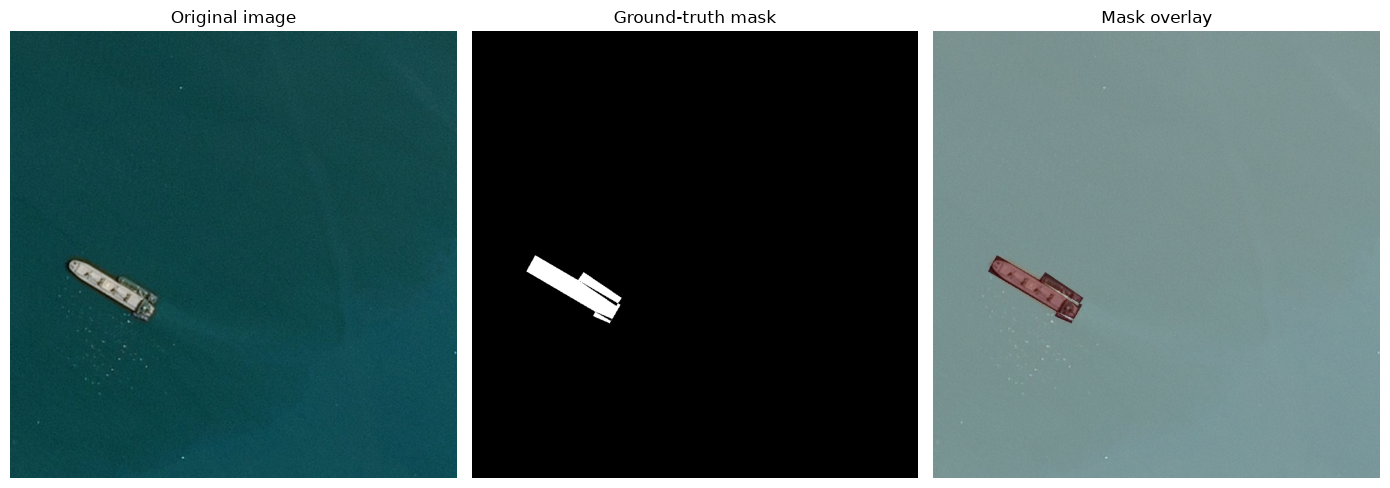

Mask shape: (768, 768)
Ship pixels: 6468


In [4]:
sample_id = "0a0df8299.jpg"

image_path = DATA_DIR / sample_id

with Image.open(image_path) as image:
    image = image.convert("RGB")

mask = get_image_mask(sample_id)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image)
axes[2].imshow(mask, cmap="Reds", alpha=0.45)
axes[2].set_title("Mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Mask shape:", mask.shape)
print("Ship pixels:", int(mask.sum()))

In [5]:
ship_image_ids = annotations.loc[
    annotations["EncodedPixels"].notna(), "ImageId"
].drop_duplicates()

print(ship_image_ids.iloc[0])

000155de5.jpg


In [6]:
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

In [7]:
class AirbusSegmentationDataset(Dataset):
    def __init__(self, image_ids, annotations, image_dir, size=256):
        self.image_ids = list(image_ids)
        self.image_dir = Path(image_dir)
        self.size = size

        # Store only non-empty RLE masks, grouped by image.
        self.rle_by_image = (
            annotations.dropna(subset=["EncodedPixels"])
            .groupby("ImageId")["EncodedPixels"]
            .apply(list)
            .to_dict()
        )

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]

        with Image.open(self.image_dir / image_id) as img:
            image = img.convert("RGB")

        mask = np.zeros((MASK_SIZE, MASK_SIZE), dtype=np.uint8)

        for rle in self.rle_by_image.get(image_id, []):
            mask |= decode_rle(rle)

        # Resize image smoothly and mask with nearest-neighbor.
        image = TF.resize(
            image,
            [self.size, self.size],
            interpolation=InterpolationMode.BILINEAR,
        )

        mask = TF.resize(
            Image.fromarray(mask),
            [self.size, self.size],
            interpolation=InterpolationMode.NEAREST,
        )

        image = TF.to_tensor(image)
        image = TF.normalize(
            image,
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        )

        mask = torch.from_numpy(np.array(mask, dtype=np.float32)).unsqueeze(0)

        return image, mask

In [8]:
labels = (
    annotations.assign(has_ship=annotations["EncodedPixels"].notna())
    .groupby("ImageId")["has_ship"]
    .any()
    .astype(int)
)

In [9]:
from sklearn.model_selection import train_test_split

all_image_ids = labels.index.to_numpy()
all_labels = labels.to_numpy()

# Stratified sample so both classes are represented.
sample_ids, _, sample_labels, _ = train_test_split(
    all_image_ids,
    all_labels,
    train_size=4000,
    random_state=42,
    stratify=all_labels,
)

train_ids, val_ids = train_test_split(
    sample_ids,
    test_size=0.2,
    random_state=42,
    stratify=sample_labels,
)

In [10]:
train_seg_dataset = AirbusSegmentationDataset(
    train_ids, annotations, DATA_DIR, size=256
)

val_seg_dataset = AirbusSegmentationDataset(
    val_ids, annotations, DATA_DIR, size=256
)

train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

val_seg_loader = DataLoader(
    val_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

print("Training images:", len(train_seg_dataset))
print("Validation images:", len(val_seg_dataset))

Training images: 3200
Validation images: 800


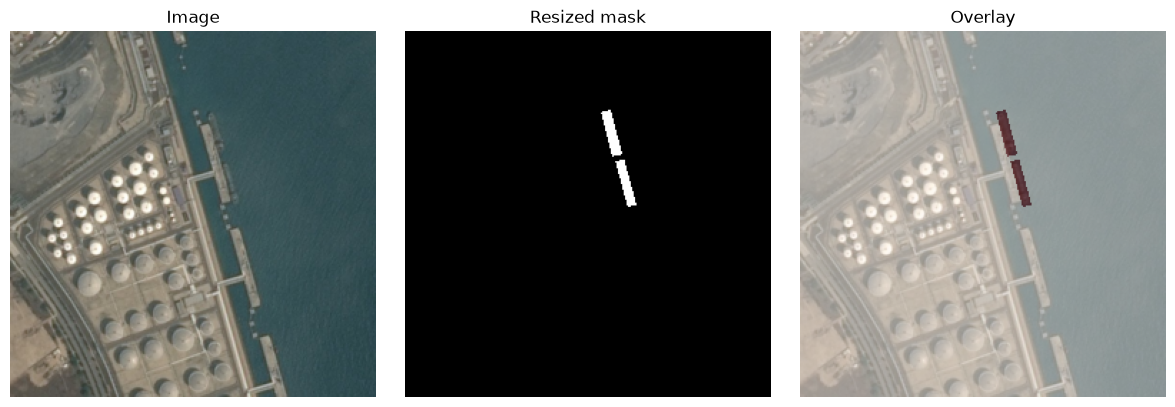

Image tensor: torch.Size([3, 256, 256])
Mask tensor: torch.Size([1, 256, 256])
Mask values: tensor([0., 1.])


In [11]:
image, mask = train_seg_dataset[0]

# Undo normalization for display.
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = (image * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(display_image)
axes[0].set_title("Image")

axes[1].imshow(mask.squeeze(0), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Resized mask")

axes[2].imshow(display_image)
axes[2].imshow(mask.squeeze(0), cmap="Reds", alpha=0.45)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image tensor:", image.shape)
print("Mask tensor:", mask.shape)
print("Mask values:", torch.unique(mask))

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18

In [13]:
class ResNet18Segmenter(nn.Module):
    def __init__(self, pretrained_encoder=None):
        super().__init__()

        backbone = resnet18(weights=None)

        if pretrained_encoder is not None:
            backbone.fc = nn.Identity()
            backbone.load_state_dict(pretrained_encoder.state_dict())

        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)

        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        def up_block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.up4 = up_block(512 + 256, 256)
        self.up3 = up_block(256 + 128, 128)
        self.up2 = up_block(128 + 64, 64)
        self.up1 = up_block(64 + 64, 64)

        self.output = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        x0 = self.stem(x)
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        d4 = F.interpolate(
            x4, size=x3.shape[-2:], mode="bilinear", align_corners=False
        )
        d4 = self.up4(torch.cat([d4, x3], dim=1))

        d3 = F.interpolate(
            d4, size=x2.shape[-2:], mode="bilinear", align_corners=False
        )
        d3 = self.up3(torch.cat([d3, x2], dim=1))

        d2 = F.interpolate(
            d3, size=x1.shape[-2:], mode="bilinear", align_corners=False
        )
        d2 = self.up2(torch.cat([d2, x1], dim=1))

        d1 = F.interpolate(
            d2, size=x0.shape[-2:], mode="bilinear", align_corners=False
        )
        d1 = self.up1(torch.cat([d1, x0], dim=1))

        logits = self.output(d1)

        return F.interpolate(
            logits, size=input_size, mode="bilinear", align_corners=False
        )


In [14]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        backbone = resnet18(weights=None)

        # Replace the classification layer with an identity.
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone

        self.projector = nn.Sequential(
            nn.Linear(feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim),
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)

        # Normalize projections for contrastive learning.
        projections = F.normalize(projections, dim=1)

        return features, projections


In [15]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimCLR().to(DEVICE)

In [16]:
segmenter = ResNet18Segmenter(pretrained_encoder=model.encoder).to(DEVICE)

images, masks = next(iter(train_seg_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = segmenter(images)

print("Input:", images.shape)
print("Target mask:", masks.shape)
print("Predicted logits:", logits.shape)
print("Parameters:", f"{sum(p.numel() for p in segmenter.parameters()):,}")

Input: torch.Size([16, 3, 256, 256])
Target mask: torch.Size([16, 1, 256, 256])
Predicted logits: torch.Size([16, 1, 256, 256])
Parameters: 14,386,817


In [17]:
def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        probabilities.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


In [18]:
def segmentation_loss(logits, masks):
    pos_weight = logits.new_tensor([10.0])

    bce = F.binary_cross_entropy_with_logits(
        logits, masks, pos_weight=pos_weight
    )

    dice = dice_loss(logits, masks)

    return bce + dice

In [19]:
images = images.to(DEVICE)
masks = masks.to(DEVICE)

segmenter.train()
segmenter.zero_grad()

logits = segmenter(images)
loss = segmentation_loss(logits, masks)

loss.backward()

print("Images device:", images.device)
print("Masks device:", masks.device)
print("Logits device:", logits.device)
print("Loss:", loss.item())
print("Backward pass: successful")

Images device: cuda:0
Masks device: cuda:0
Logits device: cuda:0
Loss: 1.6674728393554688
Backward pass: successful


In [20]:
segmenter.zero_grad(set_to_none=True)

del images, masks, logits, loss

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

In [21]:
segmenter.eval()

images, masks = next(iter(train_seg_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = segmenter(images)
    loss = segmentation_loss(logits, masks)

print(f"BCE + Dice loss: {loss.item():.4f}")

BCE + Dice loss: 1.6412


In [22]:
import time

from torch.optim import AdamW

optimizer = AdamW(segmenter.parameters(), lr=1e-4, weight_decay=1e-4)

segmenter.train()
running_loss = 0.0
steps = 200
start_time = time.time()

train_iter = iter(train_seg_loader)


In [23]:
for step in range(steps):
    try:
        images, masks = next(train_iter)
    except StopIteration:
        train_iter = iter(train_seg_loader)
        images, masks = next(train_iter)

    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    optimizer.zero_grad()

    logits = segmenter(images)
    loss = segmentation_loss(logits, masks)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (step + 1) % 25 == 0:
        print(f"Step {step + 1}/{steps} | Loss: {running_loss / 25:.4f}")
        running_loss = 0.0

print(f"\nTraining time: {(time.time() - start_time) / 60:.2f} minutes")

Step 25/200 | Loss: 1.5456
Step 50/200 | Loss: 1.4128
Step 75/200 | Loss: 1.3450
Step 100/200 | Loss: 1.3087
Step 125/200 | Loss: 1.2980
Step 150/200 | Loss: 1.2813
Step 175/200 | Loss: 1.2557
Step 200/200 | Loss: 1.2494

Training time: 0.46 minutes


In [24]:
segmenter.eval()

val_loss = 0.0
total_intersection = 0
total_union = 0
total_predicted = 0
total_actual = 0

In [25]:
with torch.no_grad():
    for images, masks in val_seg_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = segmenter(images)
        val_loss += segmentation_loss(logits, masks).item()

        predictions = (torch.sigmoid(logits) > 0.5).float()

        total_intersection += (predictions * masks).sum().item()
        total_union += ((predictions + masks) > 0).sum().item()
        total_predicted += predictions.sum().item()
        total_actual += masks.sum().item()

In [26]:
dice = (
    2 * total_intersection / (total_predicted + total_actual)
    if total_predicted + total_actual > 0
    else 0.0
)

iou = total_intersection / total_union if total_union > 0 else 0.0

print(f"Validation loss: {val_loss / len(val_seg_loader):.4f}")
print(f"Pixel Dice:      {dice:.4f}")
print(f"Pixel IoU:       {iou:.4f}")

Validation loss: 1.2364
Pixel Dice:      0.2109
Pixel IoU:       0.1179


In [27]:
import matplotlib.pyplot as plt

segmenter.eval()

images, masks = next(iter(val_seg_loader))
images = images.to(DEVICE)

with torch.no_grad():
    logits = segmenter(images)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities > 0.5).float()

print("Probability min:", probabilities.min().item())
print("Probability max:", probabilities.max().item())
print("Probability mean:", probabilities.mean().item())
print("Predicted ship pixels:", predictions.sum().item())
print("Actual ship pixels:", masks.sum().item())

Probability min: 0.12818992137908936
Probability max: 0.4734116494655609
Probability mean: 0.20052966475486755
Predicted ship pixels: 0.0
Actual ship pixels: 346.0


In [28]:
# Find validation image IDs that contain ships
ship_ids = set(
    annotations.loc[annotations["EncodedPixels"].notna(), "ImageId"]
)

val_ship_ids = [image_id for image_id in val_ids if image_id in ship_ids]

print("Validation images containing ships:", len(val_ship_ids))

Validation images containing ships: 177


In [29]:
# Build a dataset containing only ship images
ship_val_dataset = AirbusSegmentationDataset(
    val_ship_ids[:8], annotations, DATA_DIR, size=256
)

ship_val_loader = DataLoader(
    ship_val_dataset, batch_size=8, shuffle=False, num_workers=0
)

images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)

segmenter.eval()

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))


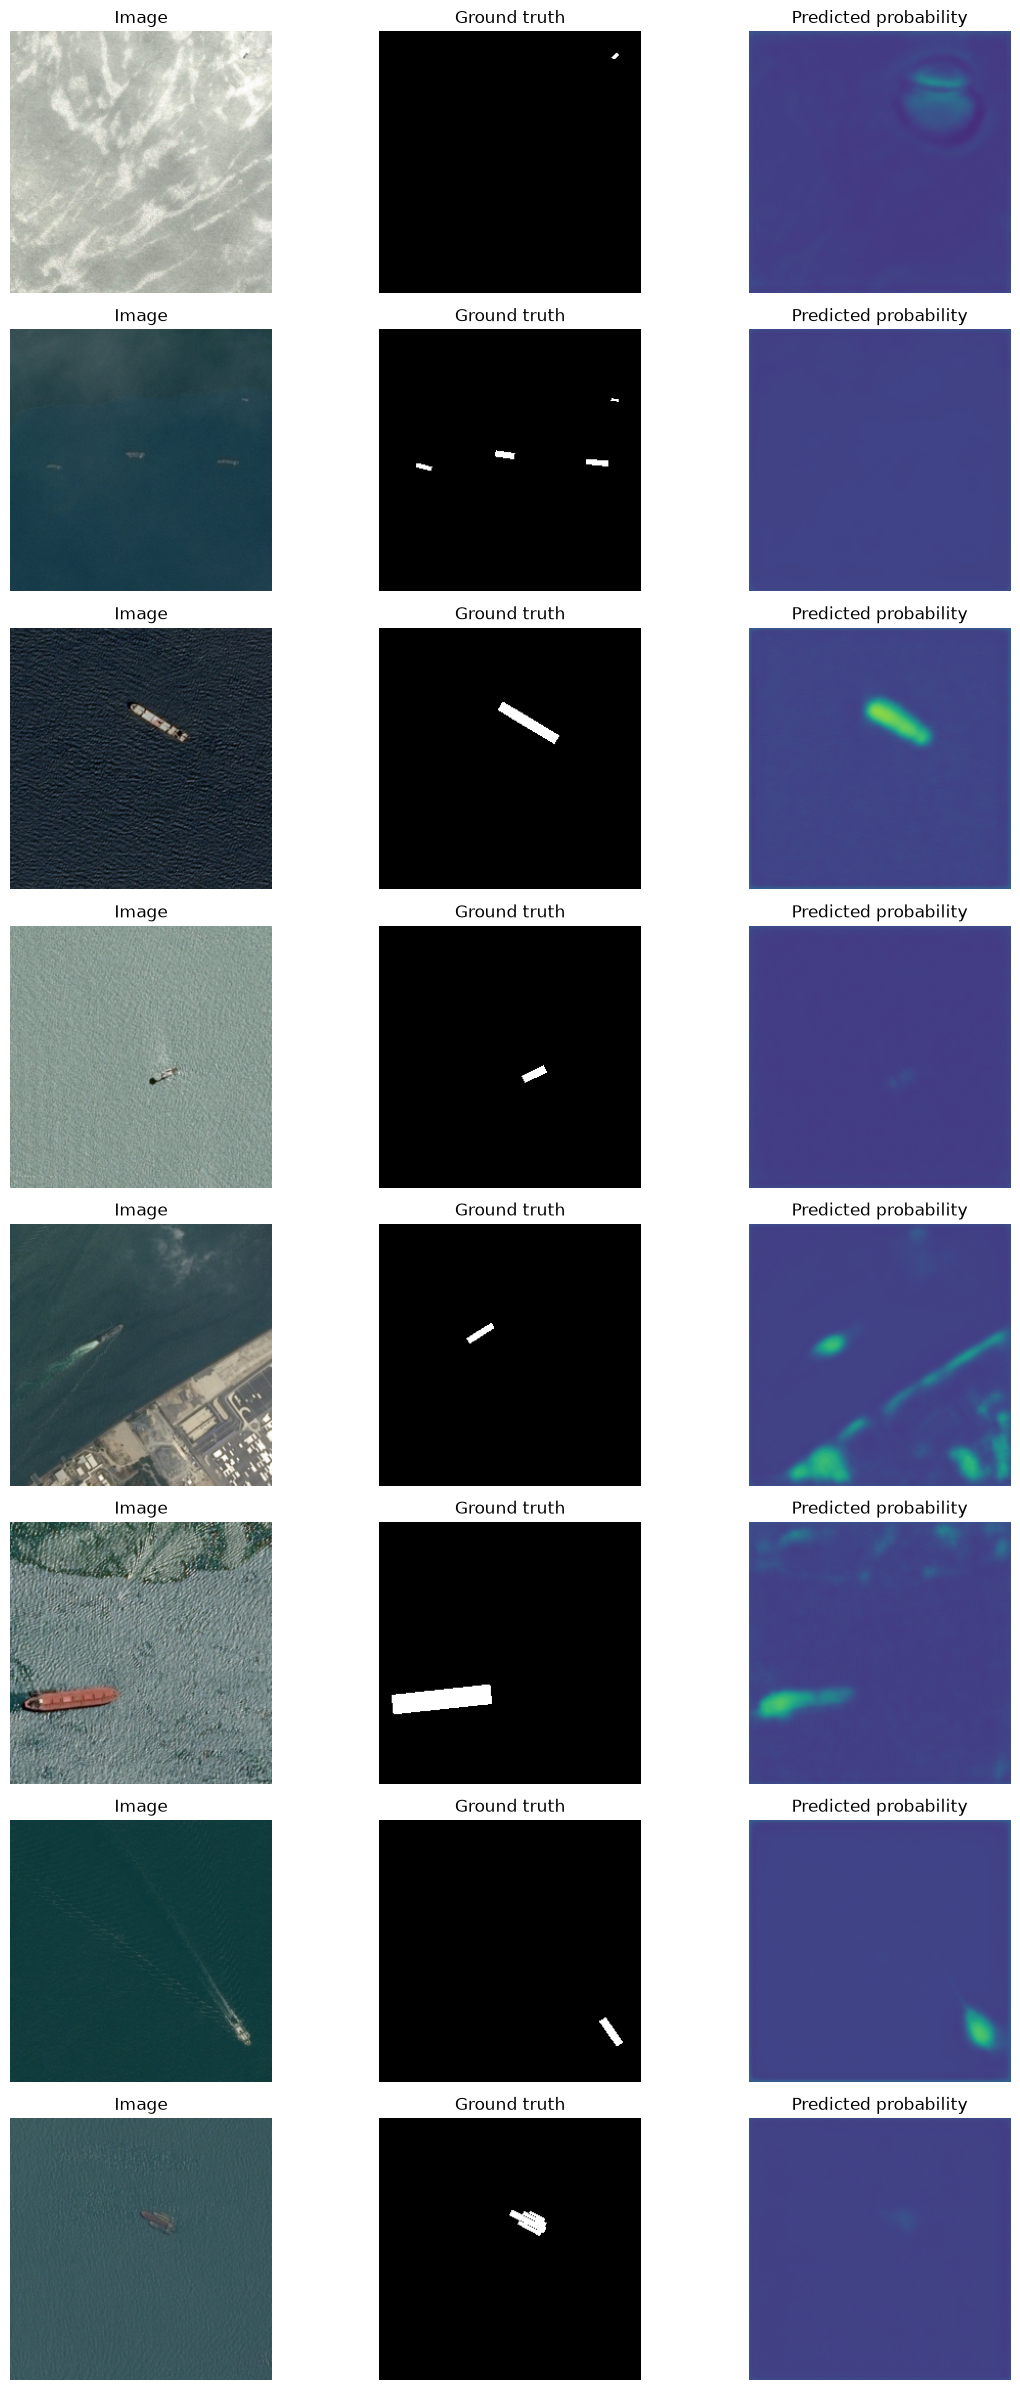

In [30]:
fig, axes = plt.subplots(len(images), 3, figsize=(12, 3 * len(images)))

for i in range(len(images)):
    image = images[i].cpu().permute(1, 2, 0).numpy()
    image = np.clip(
        image * np.array([0.229, 0.224, 0.225])
        + np.array([0.485, 0.456, 0.406]),
        0,
        1,
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Image")

    axes[i, 1].imshow(masks[i, 0].numpy(), cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(
        probabilities[i, 0].cpu().numpy(), cmap="viridis", vmin=0, vmax=1
    )
    axes[i, 2].set_title("Predicted probability")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
segmenter.eval()

images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))

In [32]:
for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    predictions = (probabilities > threshold).float()

    intersection = (predictions * masks).sum().item()
    predicted_pixels = predictions.sum().item()
    actual_pixels = masks.sum().item()

    dice = (
        2 * intersection / (predicted_pixels + actual_pixels)
        if predicted_pixels + actual_pixels > 0
        else 0.0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Predicted pixels: {predicted_pixels:.0f} | "
        f"Dice: {dice:.4f}"
    )

Threshold: 0.10 | Predicted pixels: 524288 | Dice: 0.0150
Threshold: 0.15 | Predicted pixels: 523859 | Dice: 0.0150
Threshold: 0.20 | Predicted pixels: 177219 | Dice: 0.0392
Threshold: 0.25 | Predicted pixels: 22625 | Dice: 0.1966
Threshold: 0.30 | Predicted pixels: 12214 | Dice: 0.2921
Threshold: 0.40 | Predicted pixels: 6868 | Dice: 0.3539
Threshold: 0.50 | Predicted pixels: 4295 | Dice: 0.3823


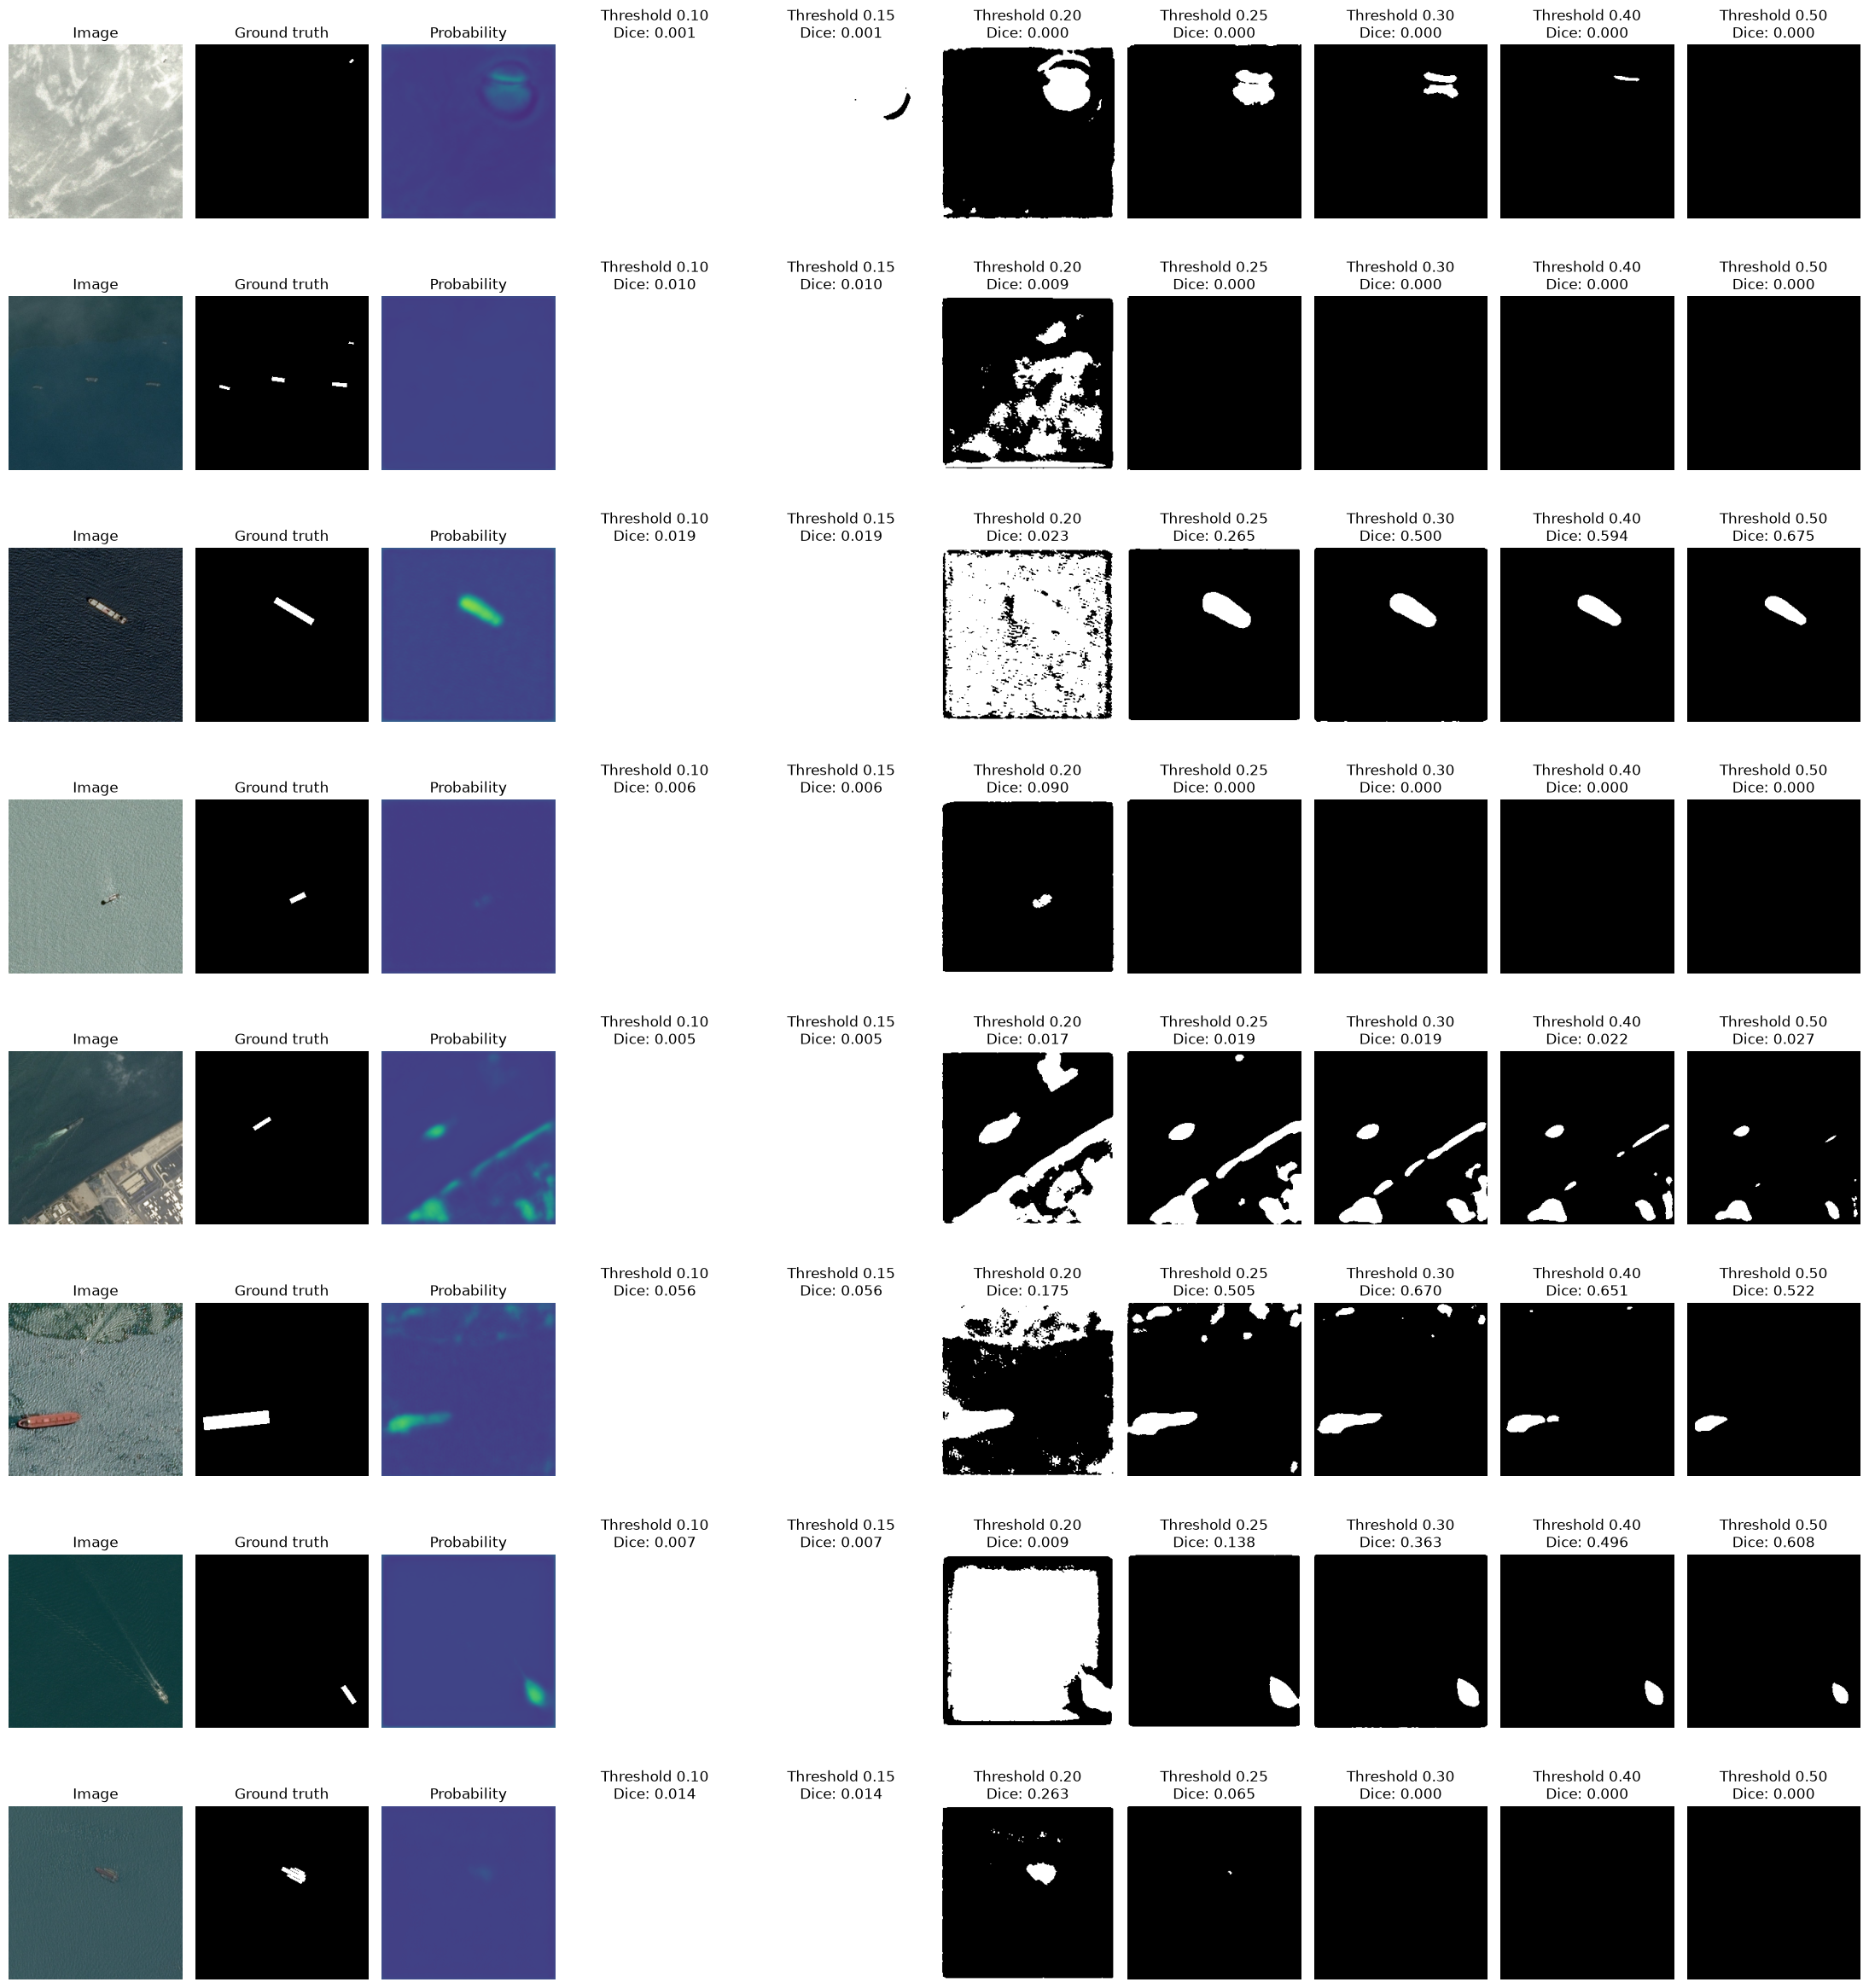

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import torch

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

segmenter.eval()

images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))

# Number of images to display
n = min(8, len(images))

fig, axes = plt.subplots(
    n, 3 + len(thresholds), figsize=(22, 3 * n), squeeze=False
)

for i in range(n):
    # Undo ImageNet normalization
    image = images[i].cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    truth = masks[i, 0].cpu().numpy()
    prob = probabilities[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Image")

    axes[i, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability")

    for j, threshold in enumerate(thresholds):
        pred = (prob > threshold).astype(np.uint8)

        intersection = np.logical_and(pred, truth > 0).sum()
        denominator = pred.sum() + (truth > 0).sum()

        dice = 2 * intersection / denominator if denominator > 0 else 1.0

        axes[i, j + 3].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, j + 3].set_title(
            f"Threshold {threshold:.2f}\nDice: {dice:.3f}"
        )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [34]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

segmenter.eval()

results = {
    t: {"intersection": 0, "predicted": 0, "actual": 0} for t in thresholds
}

with torch.no_grad():
    for images, masks in val_seg_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).bool()

        probabilities = torch.sigmoid(segmenter(images))

        for t in thresholds:
            predictions = probabilities > t

            results[t]["intersection"] += (predictions & masks).sum().item()

            results[t]["predicted"] += predictions.sum().item()
            results[t]["actual"] += masks.sum().item()

for t in thresholds:
    r = results[t]
    intersection = r["intersection"]
    predicted = r["predicted"]
    actual = r["actual"]

    dice = (
        2 * intersection / (predicted + actual) if predicted + actual else 1.0
    )

    union = predicted + actual - intersection
    iou = intersection / union if union else 1.0

    print(
        f"Threshold {t:.2f} | "
        f"Dice: {dice:.4f} | IoU: {iou:.4f} | "
        f"Predicted pixels: {predicted}"
    )

Threshold 0.10 | Dice: 0.0024 | IoU: 0.0012 | Predicted pixels: 52404712
Threshold 0.15 | Dice: 0.0024 | IoU: 0.0012 | Predicted pixels: 52292968
Threshold 0.20 | Dice: 0.0039 | IoU: 0.0019 | Predicted pixels: 30019686
Threshold 0.25 | Dice: 0.0362 | IoU: 0.0184 | Predicted pixels: 2401058
Threshold 0.30 | Dice: 0.0888 | IoU: 0.0464 | Predicted pixels: 796951
Threshold 0.40 | Dice: 0.1641 | IoU: 0.0894 | Predicted pixels: 317026
Threshold 0.50 | Dice: 0.2109 | IoU: 0.1179 | Predicted pixels: 174193


In [35]:
segmenter.train()

running_loss = 0.0
steps = 800
start_time = time.time()
train_iter = iter(train_seg_loader)

for step in range(steps):
    try:
        images, masks = next(train_iter)
    except StopIteration:
        train_iter = iter(train_seg_loader)
        images, masks = next(train_iter)

    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    optimizer.zero_grad()

    logits = segmenter(images)
    loss = segmentation_loss(logits, masks)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (step + 1) % 100 == 0:
        print(f"Step {step + 1}/{steps} | Loss: {running_loss / 100:.4f}")
        running_loss = 0.0

print(f"\nTraining time: {(time.time() - start_time) / 60:.2f} minutes")

Step 100/800 | Loss: 1.2181
Step 200/800 | Loss: 1.1816
Step 300/800 | Loss: 1.1578
Step 400/800 | Loss: 1.1323
Step 500/800 | Loss: 1.1123
Step 600/800 | Loss: 1.0922
Step 700/800 | Loss: 1.0790
Step 800/800 | Loss: 1.0664

Training time: 1.80 minutes


In [36]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

segmenter.eval()

results = {
    t: {"intersection": 0, "predicted": 0, "actual": 0, "loss": 0.0}
    for t in thresholds
}
total_val_loss = 0.0

with torch.no_grad():
    for images, masks in val_seg_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).bool()

        logits = segmenter(images)
        probabilities = torch.sigmoid(logits)

        total_val_loss += segmentation_loss(logits, masks.float()).item()

        for t in thresholds:
            predictions = probabilities > t
            r = results[t]

            r["intersection"] += (predictions & masks).sum().item()
            r["predicted"] += predictions.sum().item()
            r["actual"] += masks.sum().item()

print(f"Validation loss: {total_val_loss / len(val_seg_loader):.4f}\n")

for t in thresholds:
    r = results[t]
    intersection = r["intersection"]
    predicted = r["predicted"]
    actual = r["actual"]

    dice = (
        2 * intersection / (predicted + actual) if predicted + actual else 1.0
    )
    union = predicted + actual - intersection
    iou = intersection / union if union else 1.0

    print(
        f"Threshold {t:.2f} | Dice: {dice:.4f} | "
        f"IoU: {iou:.4f} | Predicted pixels: {predicted}"
    )

Validation loss: 1.0561

Threshold 0.10 | Dice: 0.1615 | IoU: 0.0878 | Predicted pixels: 651756
Threshold 0.15 | Dice: 0.2348 | IoU: 0.1330 | Predicted pixels: 413032
Threshold 0.20 | Dice: 0.2776 | IoU: 0.1612 | Predicted pixels: 329869
Threshold 0.25 | Dice: 0.3088 | IoU: 0.1826 | Predicted pixels: 282441
Threshold 0.30 | Dice: 0.3340 | IoU: 0.2005 | Predicted pixels: 249713
Threshold 0.40 | Dice: 0.3736 | IoU: 0.2297 | Predicted pixels: 205025
Threshold 0.50 | Dice: 0.4071 | IoU: 0.2555 | Predicted pixels: 172948


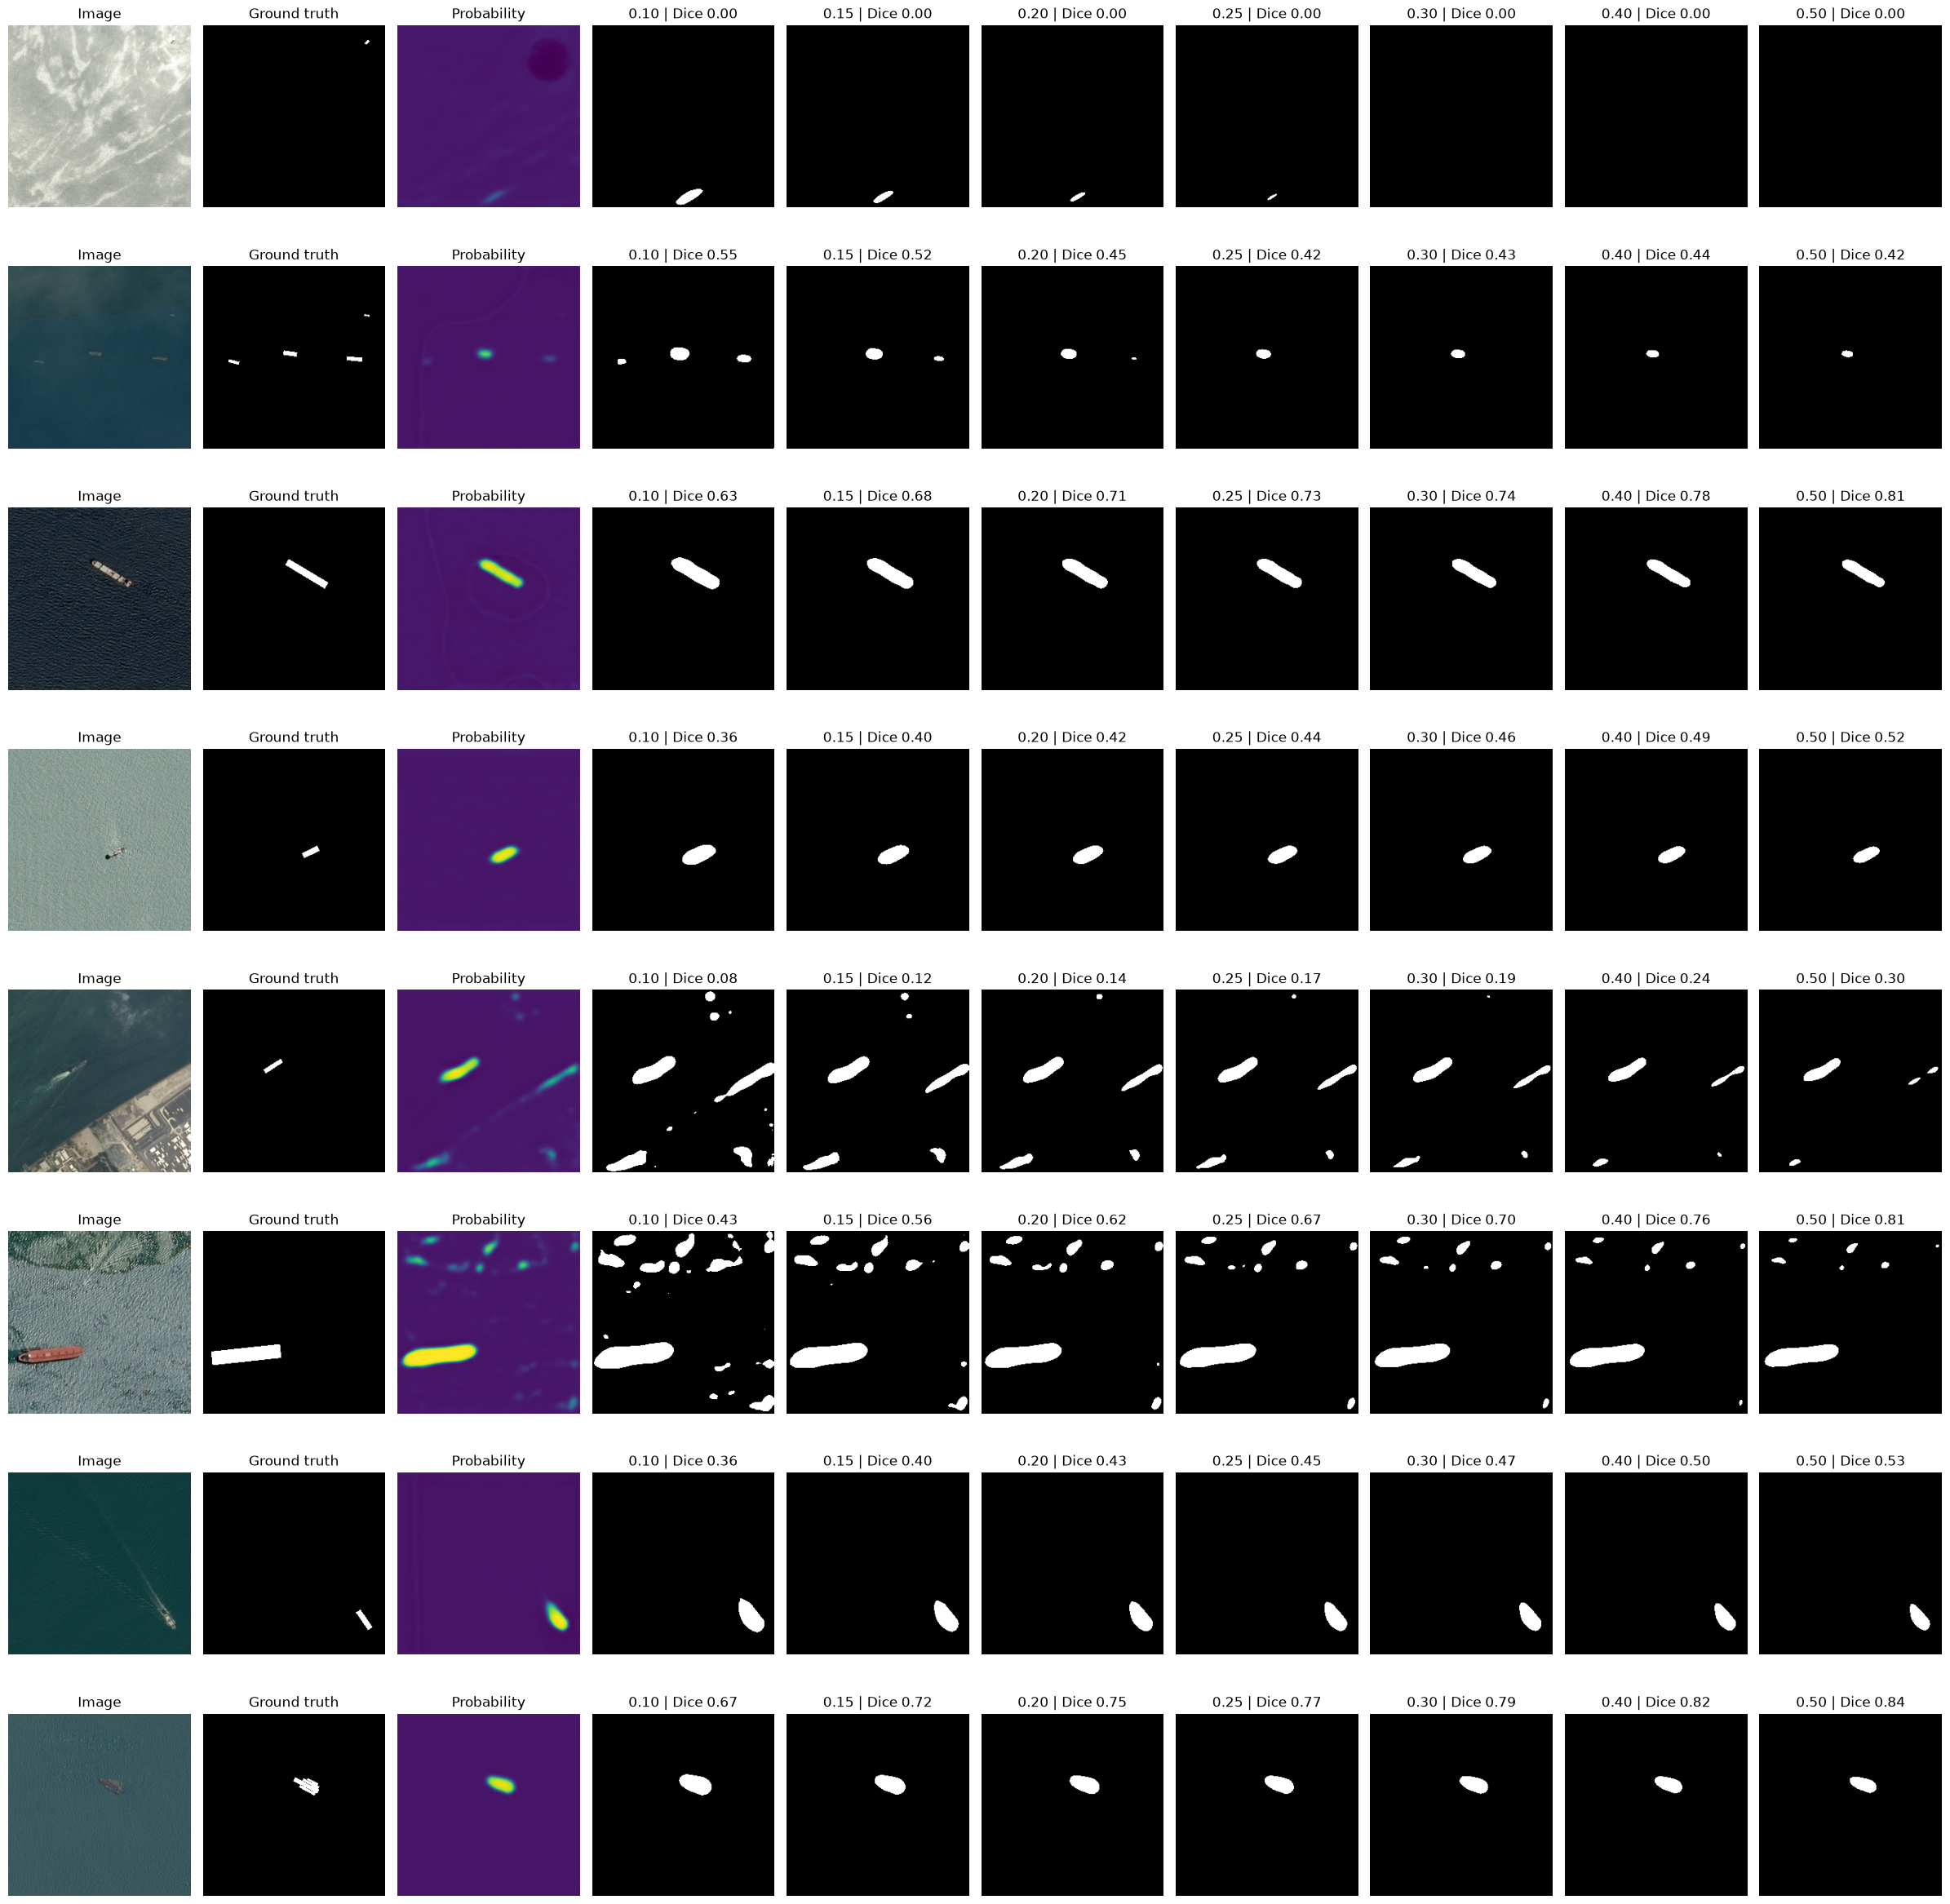

In [37]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

segmenter.eval()

# Reuse the same validation images for a fair visual comparison
images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))

n = min(8, len(images))

fig, axes = plt.subplots(
    n, 3 + len(thresholds), figsize=(24, 3 * n), squeeze=False
)

for i in range(n):
    image = images[i].cpu().permute(1, 2, 0).numpy()
    image = np.clip(
        image * np.array([0.229, 0.224, 0.225])
        + np.array([0.485, 0.456, 0.406]),
        0,
        1,
    )

    truth = masks[i, 0].cpu().numpy() > 0.5
    prob = probabilities[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Image")

    axes[i, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability")

    for j, threshold in enumerate(thresholds):
        pred = prob > threshold

        intersection = np.logical_and(pred, truth).sum()
        denominator = pred.sum() + truth.sum()
        dice = 2 * intersection / denominator if denominator > 0 else 1.0

        ax = axes[i, j + 3]
        ax.imshow(pred, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{threshold:.2f} | Dice {dice:.2f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
from pathlib import Path

import torch

checkpoint_dir = Path("../checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "varuna_segmentation_baseline.pt"

torch.save(
    {
        "model_state_dict": segmenter.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "threshold": 0.25,
        "image_size": 256,
        "training_steps": 1000,
        "validation_dice": 0.2517,
        "validation_iou": 0.1439,
    },
    checkpoint_path,
)

print(f"Checkpoint saved: {checkpoint_path.resolve()}")

Checkpoint saved: /home/abhi/Dev/varuna-ssl/checkpoints/varuna_segmentation_baseline.pt


In [39]:
import numpy as np
from sklearn.model_selection import train_test_split

# Keep the existing validation set unchanged
existing_val_ids = set(val_ids)

# Select additional images from outside the existing validation set
remaining_ids = np.array(
    [image_id for image_id in labels.index if image_id not in existing_val_ids]
)

remaining_labels = labels.loc[remaining_ids].to_numpy()

# Add 8,000 images, stratified by ship presence
additional_ids, _ = train_test_split(
    remaining_ids, train_size=8000, random_state=43, stratify=remaining_labels
)

# Combine existing training images with the additional images
expanded_train_ids = np.concatenate([np.asarray(train_ids), additional_ids])

print("Training images:", len(expanded_train_ids))
print("Validation images:", len(val_ids))
print(
    "Training images containing ships:",
    int(labels.loc[expanded_train_ids].sum()),
)

Training images: 11200
Validation images: 800
Training images containing ships: 2475


In [40]:
# Remove duplicate image IDs while preserving order
expanded_train_ids = list(dict.fromkeys(expanded_train_ids))

print("Unique training images:", len(expanded_train_ids))
print("Validation images:", len(val_ids))
print("Overlap with validation:", len(set(expanded_train_ids) & set(val_ids)))

train_seg_dataset = AirbusSegmentationDataset(
    expanded_train_ids, annotations, DATA_DIR, size=256
)

train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    drop_last=True,
)

print("Training batches per epoch:", len(train_seg_loader))

Unique training images: 11050
Validation images: 800
Overlap with validation: 0
Training batches per epoch: 690


In [41]:
segmenter.train()

running_loss = 0.0
start_time = time.time()

for step, (images, masks) in enumerate(train_seg_loader, start=1):
    images = images.to(DEVICE)
    masks = masks.to(DEVICE)

    optimizer.zero_grad()

    logits = segmenter(images)
    loss = segmentation_loss(logits, masks)

    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if step % 50 == 0:
        print(
            f"Batch {step}/{len(train_seg_loader)} | "
            f"Loss: {running_loss / 50:.4f}"
        )
        running_loss = 0.0

print(f"\nEpoch time: {(time.time() - start_time) / 60:.2f} minutes")

Batch 50/690 | Loss: 1.0584
Batch 100/690 | Loss: 1.0508
Batch 150/690 | Loss: 1.0508
Batch 200/690 | Loss: 1.0415
Batch 250/690 | Loss: 1.0378
Batch 300/690 | Loss: 1.0350
Batch 350/690 | Loss: 1.0394
Batch 400/690 | Loss: 1.0271
Batch 450/690 | Loss: 1.0261
Batch 500/690 | Loss: 1.0194
Batch 550/690 | Loss: 1.0123
Batch 600/690 | Loss: 1.0043
Batch 650/690 | Loss: 1.0066

Epoch time: 1.54 minutes


In [42]:
segmenter.eval()

results = {
    t: {"intersection": 0, "predicted": 0, "actual": 0} for t in thresholds
}
total_val_loss = 0.0

with torch.no_grad():
    for images, masks in val_seg_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE).bool()

        logits = segmenter(images)
        probabilities = torch.sigmoid(logits)

        total_val_loss += segmentation_loss(logits, masks.float()).item()

        for t in thresholds:
            predictions = probabilities > t
            r = results[t]

            r["intersection"] += (predictions & masks).sum().item()
            r["predicted"] += predictions.sum().item()
            r["actual"] += masks.sum().item()

print(f"Validation loss: {total_val_loss / len(val_seg_loader):.4f}\n")

Validation loss: 1.0042



In [43]:
for t in thresholds:
    r = results[t]
    intersection = r["intersection"]
    predicted = r["predicted"]
    actual = r["actual"]

    dice = (
        2 * intersection / (predicted + actual) if predicted + actual else 1.0
    )
    union = predicted + actual - intersection
    iou = intersection / union if union else 1.0

    print(
        f"Threshold {t:.2f} | Dice: {dice:.4f} | "
        f"IoU: {iou:.4f} | Predicted pixels: {predicted}"
    )

Threshold 0.10 | Dice: 0.1028 | IoU: 0.0542 | Predicted pixels: 1074306
Threshold 0.15 | Dice: 0.1282 | IoU: 0.0685 | Predicted pixels: 833723
Threshold 0.20 | Dice: 0.1463 | IoU: 0.0789 | Predicted pixels: 713266
Threshold 0.25 | Dice: 0.1618 | IoU: 0.0880 | Predicted pixels: 631269
Threshold 0.30 | Dice: 0.1761 | IoU: 0.0965 | Predicted pixels: 568270
Threshold 0.40 | Dice: 0.2028 | IoU: 0.1128 | Predicted pixels: 473490
Threshold 0.50 | Dice: 0.2313 | IoU: 0.1307 | Predicted pixels: 397226


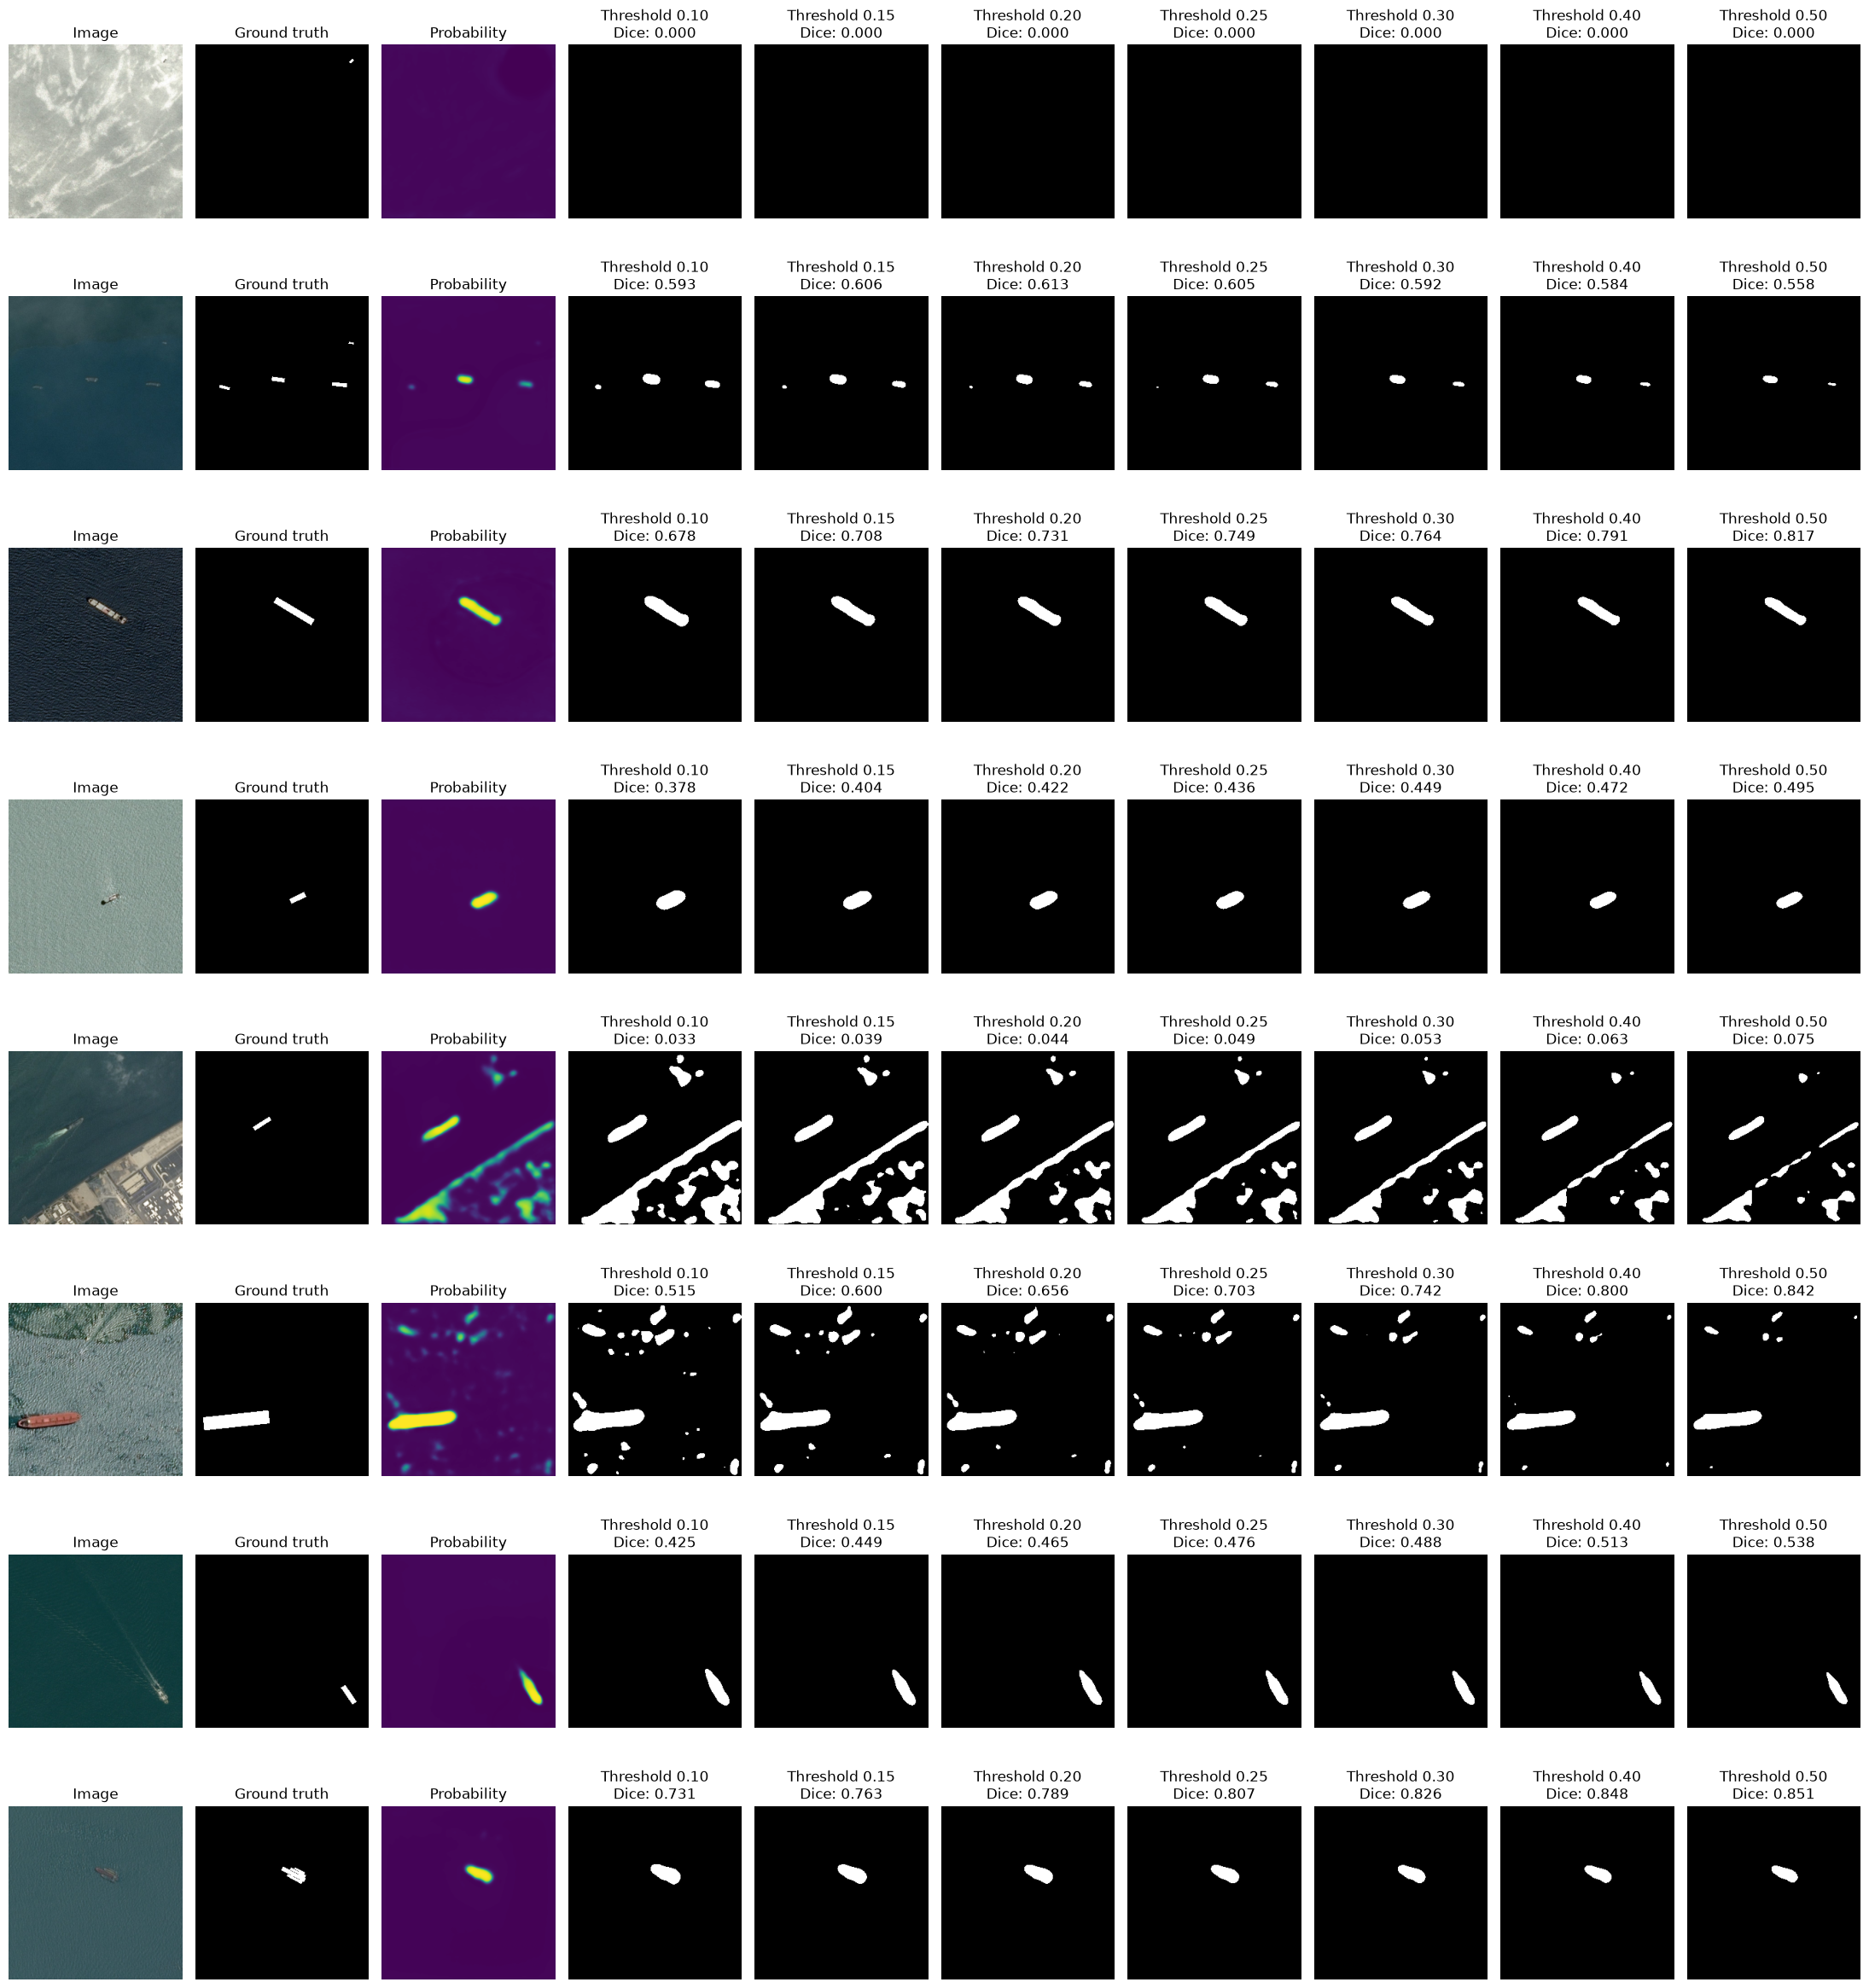

In [44]:
segmenter.eval()

# Use the same ship-containing validation images as before
images, masks = next(iter(ship_val_loader))
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    probabilities = torch.sigmoid(segmenter(images))

n = min(8, len(images))

fig, axes = plt.subplots(
    n, 3 + len(thresholds), figsize=(22, 3 * n), squeeze=False
)

for i in range(n):
    # Restore the original image colors
    image = images[i].cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    truth = masks[i, 0].cpu().numpy() > 0.5
    prob = probabilities[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Image")

    axes[i, 1].imshow(truth, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(prob, cmap="viridis", vmin=0, vmax=1)
    axes[i, 2].set_title("Probability")

    for j, threshold in enumerate(thresholds):
        pred = prob > threshold

        intersection = np.logical_and(pred, truth).sum()
        denominator = pred.sum() + truth.sum()
        dice = 2 * intersection / denominator if denominator > 0 else 1.0

        ax = axes[i, j + 3]
        ax.imshow(pred, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Threshold {threshold:.2f}\nDice: {dice:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()